In [ ]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('dark_background')
print("✅ Library berhasil di-import!")

In [2]:
import pandas as pd

# Load dataset clean dari Praktikum 01
df = pd.read_csv('Well_Dataset_Clean.csv')
print(f"📊 Dimensi Data: {df.shape[0]:,} baris × {df.shape[1]} kolom")
print(f"📋 Kolom:")
for i, col in enumerate(df.columns, 1):
    print(f"   {i:2d}. {col}")

📊 Dimensi Data: 2,058 baris × 17 kolom
📋 Kolom:
    1. Formation
    2. TMD (m)
    3. TVD (m)
    4. ROP (m/hr)
    5. WOB (ton)
    6. FR (gpm)
    7. SPP (psi)
    8. RPM (rpm)
    9. TQ (lb.ft)
   10. MW IN (ppg)
   11. MW OUT (ppg)
   12. RETURN (%)
   13. BIT TIME (hr)
   14. DATE TIME
   15. MW_DIFF
   16. DEPTH_CAT
   17. FORMATION_CODE


In [5]:
# Encoding DEPTH_CAT (ordinal: Shallow < Medium < Deep < Very Deep)
from sklearn.preprocessing import OrdinalEncoder

depth_order = ['Shallow', 'Medium', 'Deep', 'Very Deep']
oe = OrdinalEncoder(categories=[depth_order])
df['DEPTH_CAT_encoded'] = oe.fit_transform(df[['DEPTH_CAT']]).astype(int)

print("🏷️ Ordinal Encoding — DEPTH_CAT:")
for cat, code in zip(depth_order, range(4)):
    print(f"   {cat:12s} → {code}")

🏷️ Ordinal Encoding — DEPTH_CAT:
   Shallow      → 0
   Medium       → 1
   Deep         → 2
   Very Deep    → 3


In [6]:
# Definisi fitur dan target
feature_cols = [
    'TMD (m)', 'TVD (m)', 'WOB (ton)', 'FR (gpm)', 'SPP (psi)',
    'RPM (rpm)', 'TQ (lb.ft)', 'MW IN (ppg)', 'MW OUT (ppg)',
    'RETURN (%)', 'BIT TIME (hr)',   # 11 fitur asli
    'MW_DIFF', 'FORMATION_CODE',       # 2 fitur dari Praktikum 01
    'DEPTH_CAT_encoded'               # 1 fitur encoded baru
]
target_col = 'ROP (m/hr)'

X = df[feature_cols].copy()
y = df[target_col].copy()

print(f"📥 Fitur (X): {len(feature_cols)} variabel")
for i, col in enumerate(feature_cols, 1):
    print(f"   {i:2d}. {col}")
print(f"\n🎯 Target (y): {target_col}")
print(f"📊 X shape: {X.shape} | y shape: {y.shape}")

📥 Fitur (X): 14 variabel
    1. TMD (m)
    2. TVD (m)
    3. WOB (ton)
    4. FR (gpm)
    5. SPP (psi)
    6. RPM (rpm)
    7. TQ (lb.ft)
    8. MW IN (ppg)
    9. MW OUT (ppg)
   10. RETURN (%)
   11. BIT TIME (hr)
   12. MW_DIFF
   13. FORMATION_CODE
   14. DEPTH_CAT_encoded

🎯 Target (y): ROP (m/hr)
📊 X shape: (2058, 14) | y shape: (2058,)


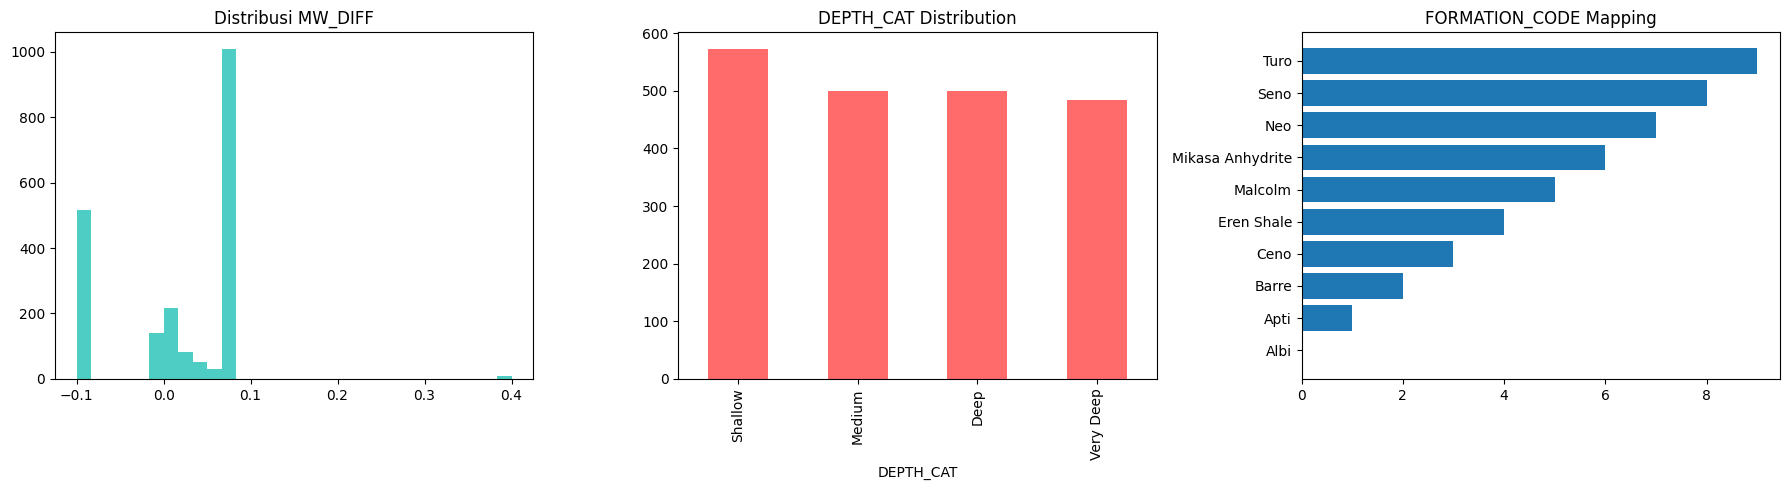

In [10]:
# Visualisasi fitur engineering
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].hist(df['MW_DIFF'], bins=30, color='#4ecdc4')
axes[0].set_title('Distribusi MW_DIFF')
df['DEPTH_CAT'].value_counts().reindex(depth_order).plot.bar(ax=axes[1], color='#ff6b6b'), axes[1].set_title('DEPTH_CAT Distribution')
axes[1].set_title('DEPTH_CAT Distribution')
# FORMATION_CODE mapping
fm = df.groupby('FORMATION_CODE')['Formation'].first().reset_index()
axes[2].barh(fm['Formation'], fm['FORMATION_CODE'])
axes[2].set_title('FORMATION_CODE Mapping')
plt.tight_layout(); plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_20116\3071716100.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


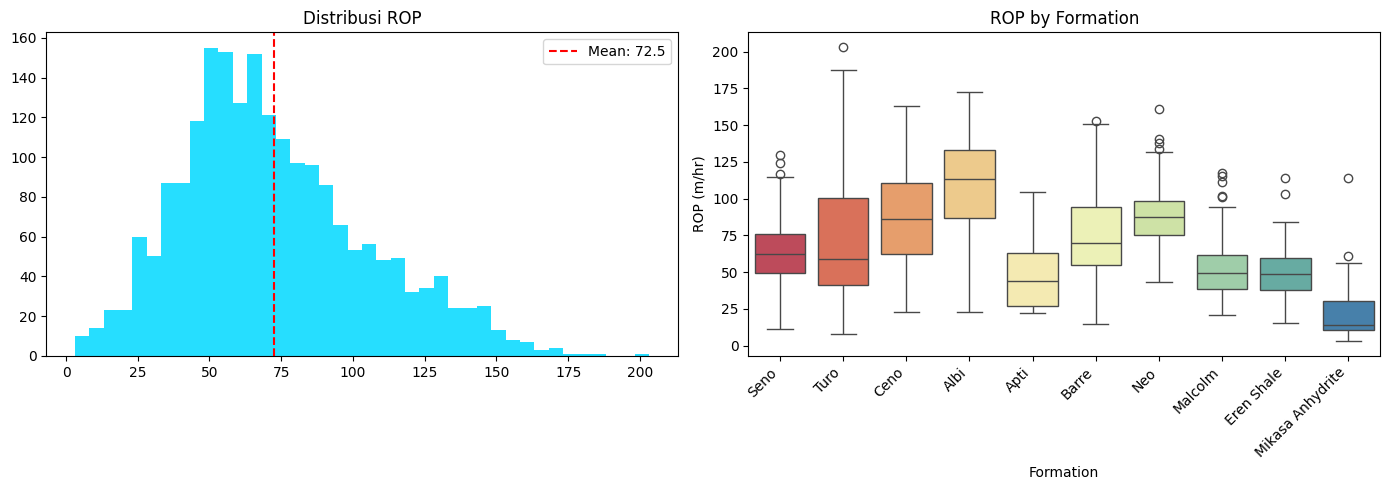

In [13]:
import seaborn as sns

# Distribusi target ROP
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df[target_col], bins=40, color='#00d9ff', alpha=0.85)
axes[0].axvline(df[target_col].mean(), color='red', ls='--', label=f'Mean: {df[target_col].mean():.1f}')
axes[0].legend()
axes[0].set_title('Distribusi ROP')

# Boxplot per formasi dengan warna bervariasi menggunakan Seaborn (diperbaiki)
sns.boxplot(
    data=df,
    x='Formation',
    y=target_col,
    ax=axes[1],
    palette='Spectral'
)
axes[1].set_title('ROP by Formation')

# Mengatur ticks secara eksplisit sebelum mengubah ticklabels untuk menghindari UserWarning
axes[1].set_xticks(range(len(df['Formation'].unique())))
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout(); plt.show()

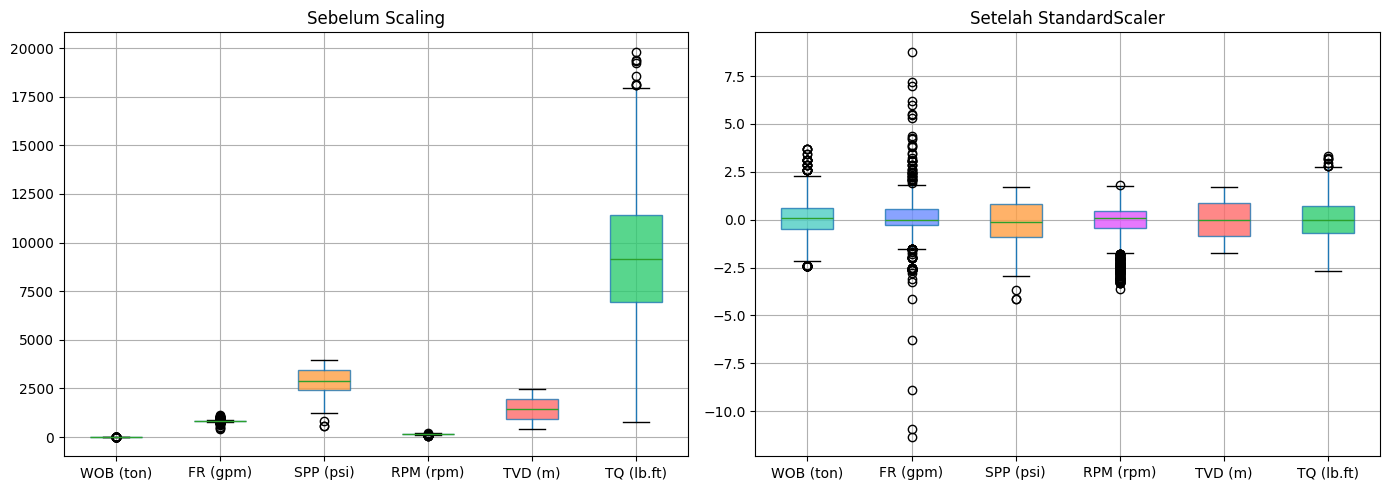

In [17]:
from sklearn.preprocessing import StandardScaler

# Demo: Before vs After Scaling
scaler_demo = StandardScaler()
X_demo = pd.DataFrame(scaler_demo.fit_transform(X), columns=X.columns)

show = ['WOB (ton)', 'FR (gpm)', 'SPP (psi)', 'RPM (rpm)', 'TVD (m)', 'TQ (lb.ft)']
warna = ['#4ecdc4', '#6c8cff', '#ff9f43', '#e056fd', '#ff6b6b', '#2ecc71']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

X[show].boxplot(ax=axes[0], patch_artist=True)
axes[0].set_title('Sebelum Scaling')

X_demo[show].boxplot(ax=axes[1], patch_artist=True)
axes[1].set_title('Setelah StandardScaler')

# Beri warna berbeda pada setiap box di kedua grafik
for ax in axes:
    for box, color in zip(ax.patches, warna):
        box.set_facecolor(color)
        box.set_alpha(0.8)

plt.tight_layout()
plt.show()

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
# Scaling SETELAH split (mencegah data leakage!)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),  # transform saja, BUKAN fit_transform!
    columns=X_test.columns, index=X_test.index
)

print(f"📊 Train set: {X_train.shape[0]:,} data ({X_train.shape[0]/len(X)*100:.0f}%)")
print(f"📊 Test set:  {X_test.shape[0]:,} data ({X_test.shape[0]/len(X)*100:.0f}%)")
print(f"✅ Scaling selesai (fit pada train, transform pada test)")

📊 Train set: 1,646 data (80%)
📊 Test set:  412 data (20%)
✅ Scaling selesai (fit pada train, transform pada test)


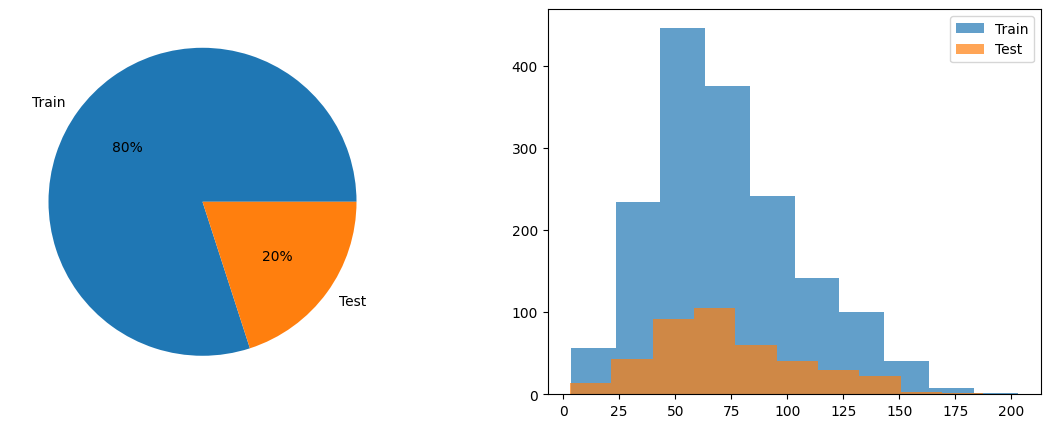

In [21]:
# Visualisasi proporsi dan distribusi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].pie([len(X_train), len(X_test)], labels=['Train', 'Test'], autopct='%1.0f%%')
axes[1].hist(y_train, alpha=0.7, label='Train')
axes[1].hist(y_test, alpha=0.7, label='Test')
axes[1].legend()
plt.show()

In [24]:


# Training Linear Regression (data SCALED)
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

print("📊 Linear Regression — Hasil Evaluasi:")
print(f"   MAE  = {mean_absolute_error(y_test, y_pred_lr):.4f} m/hr")
print(f"   RMSE = {np.sqrt(mean_squared_error(y_test, y_pred_lr)):.4f} m/hr")
print(f"   R²   = {r2_score(y_test, y_pred_lr):.4f}")

📊 Linear Regression — Hasil Evaluasi:
   MAE  = 18.7175 m/hr
   RMSE = 29.3290 m/hr
   R²   = 0.2112


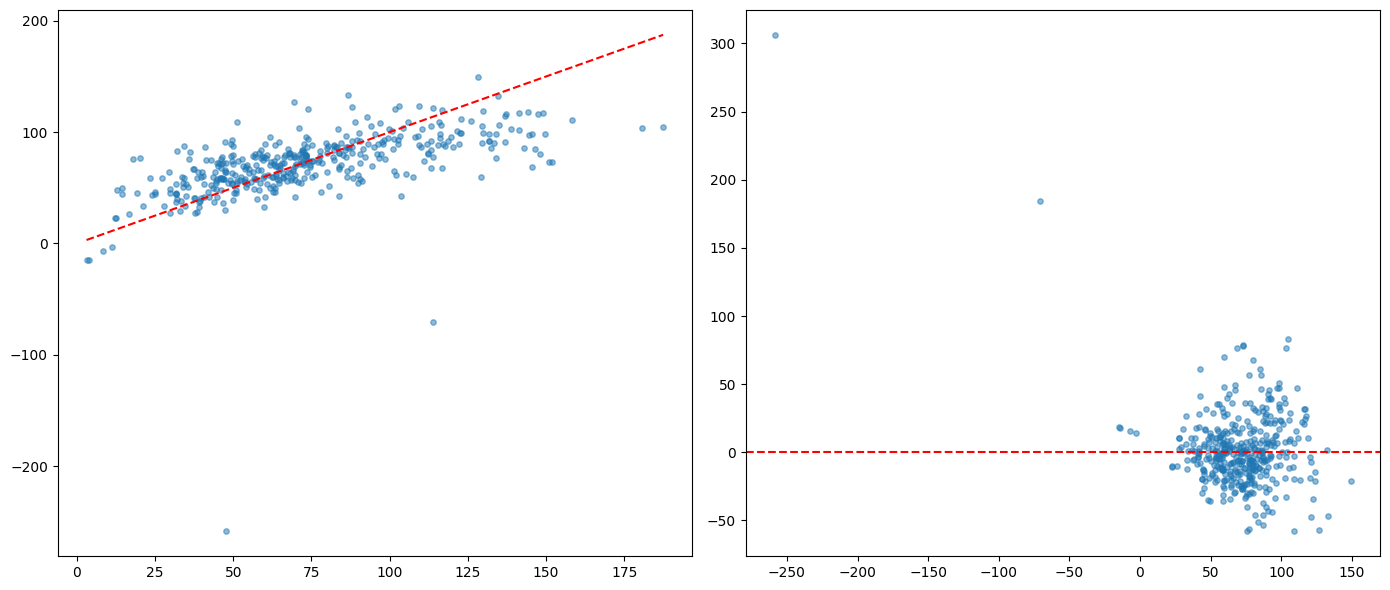

In [25]:
# Predicted vs Actual + Residual Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(y_test, y_pred_lr, alpha=0.5, s=15)
axes[0].plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--')
residuals = y_test - y_pred_lr
axes[1].scatter(y_pred_lr, residuals, alpha=0.5, s=15)
axes[1].axhline(0, color='red', ls='--')
plt.tight_layout(); plt.show()

Intercept: 72.3105
          Feature    Coefficient
          TMD (m) -257004.721969
DEPTH_CAT_encoded     -11.657111
        WOB (ton)      -6.819877
          MW_DIFF      -5.337104
   FORMATION_CODE      -3.896986
       RETURN (%)       0.626925
         FR (gpm)       1.728745
       TQ (lb.ft)       4.851771
     MW OUT (ppg)       5.960459
        RPM (rpm)       7.614782
      MW IN (ppg)       7.948291
        SPP (psi)      21.597694
    BIT TIME (hr)      49.543723
          TVD (m)  256925.208535


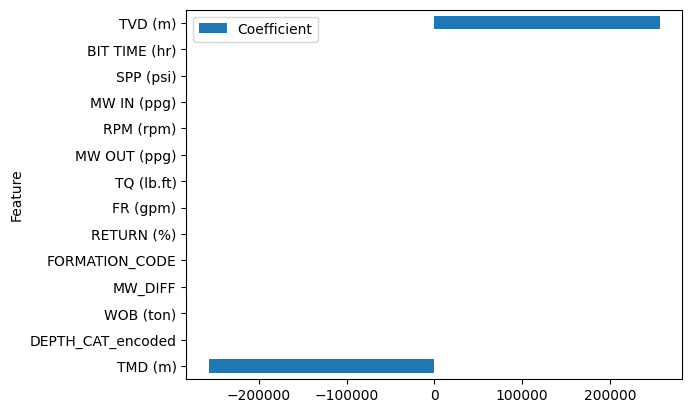

In [26]:
# Koefisien model
coef_df = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lr.coef_
}).sort_values('Coefficient')
print(f"Intercept: {lr.intercept_:.4f}")
print(coef_df.to_string(index=False))
coef_df.plot.barh(x='Feature', y='Coefficient'); plt.show()

In [28]:
from sklearn.tree import DecisionTreeRegressor
# Pastikan numpy dan sklearn.metrics sudah diimpor di sel atasnya

# Training Decision Tree (tanpa scaling!)
dt = DecisionTreeRegressor(max_depth=8, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print("🌳 Decision Tree — Hasil Evaluasi:")
print(f"   MAE  = {mean_absolute_error(y_test, y_pred_dt):.4f} m/hr")
print(f"   RMSE = {np.sqrt(mean_squared_error(y_test, y_pred_dt)):.4f} m/hr")
print(f"   R²   = {r2_score(y_test, y_pred_dt):.4f}")

🌳 Decision Tree — Hasil Evaluasi:
   MAE  = 14.0066 m/hr
   RMSE = 20.0478 m/hr
   R²   = 0.6315


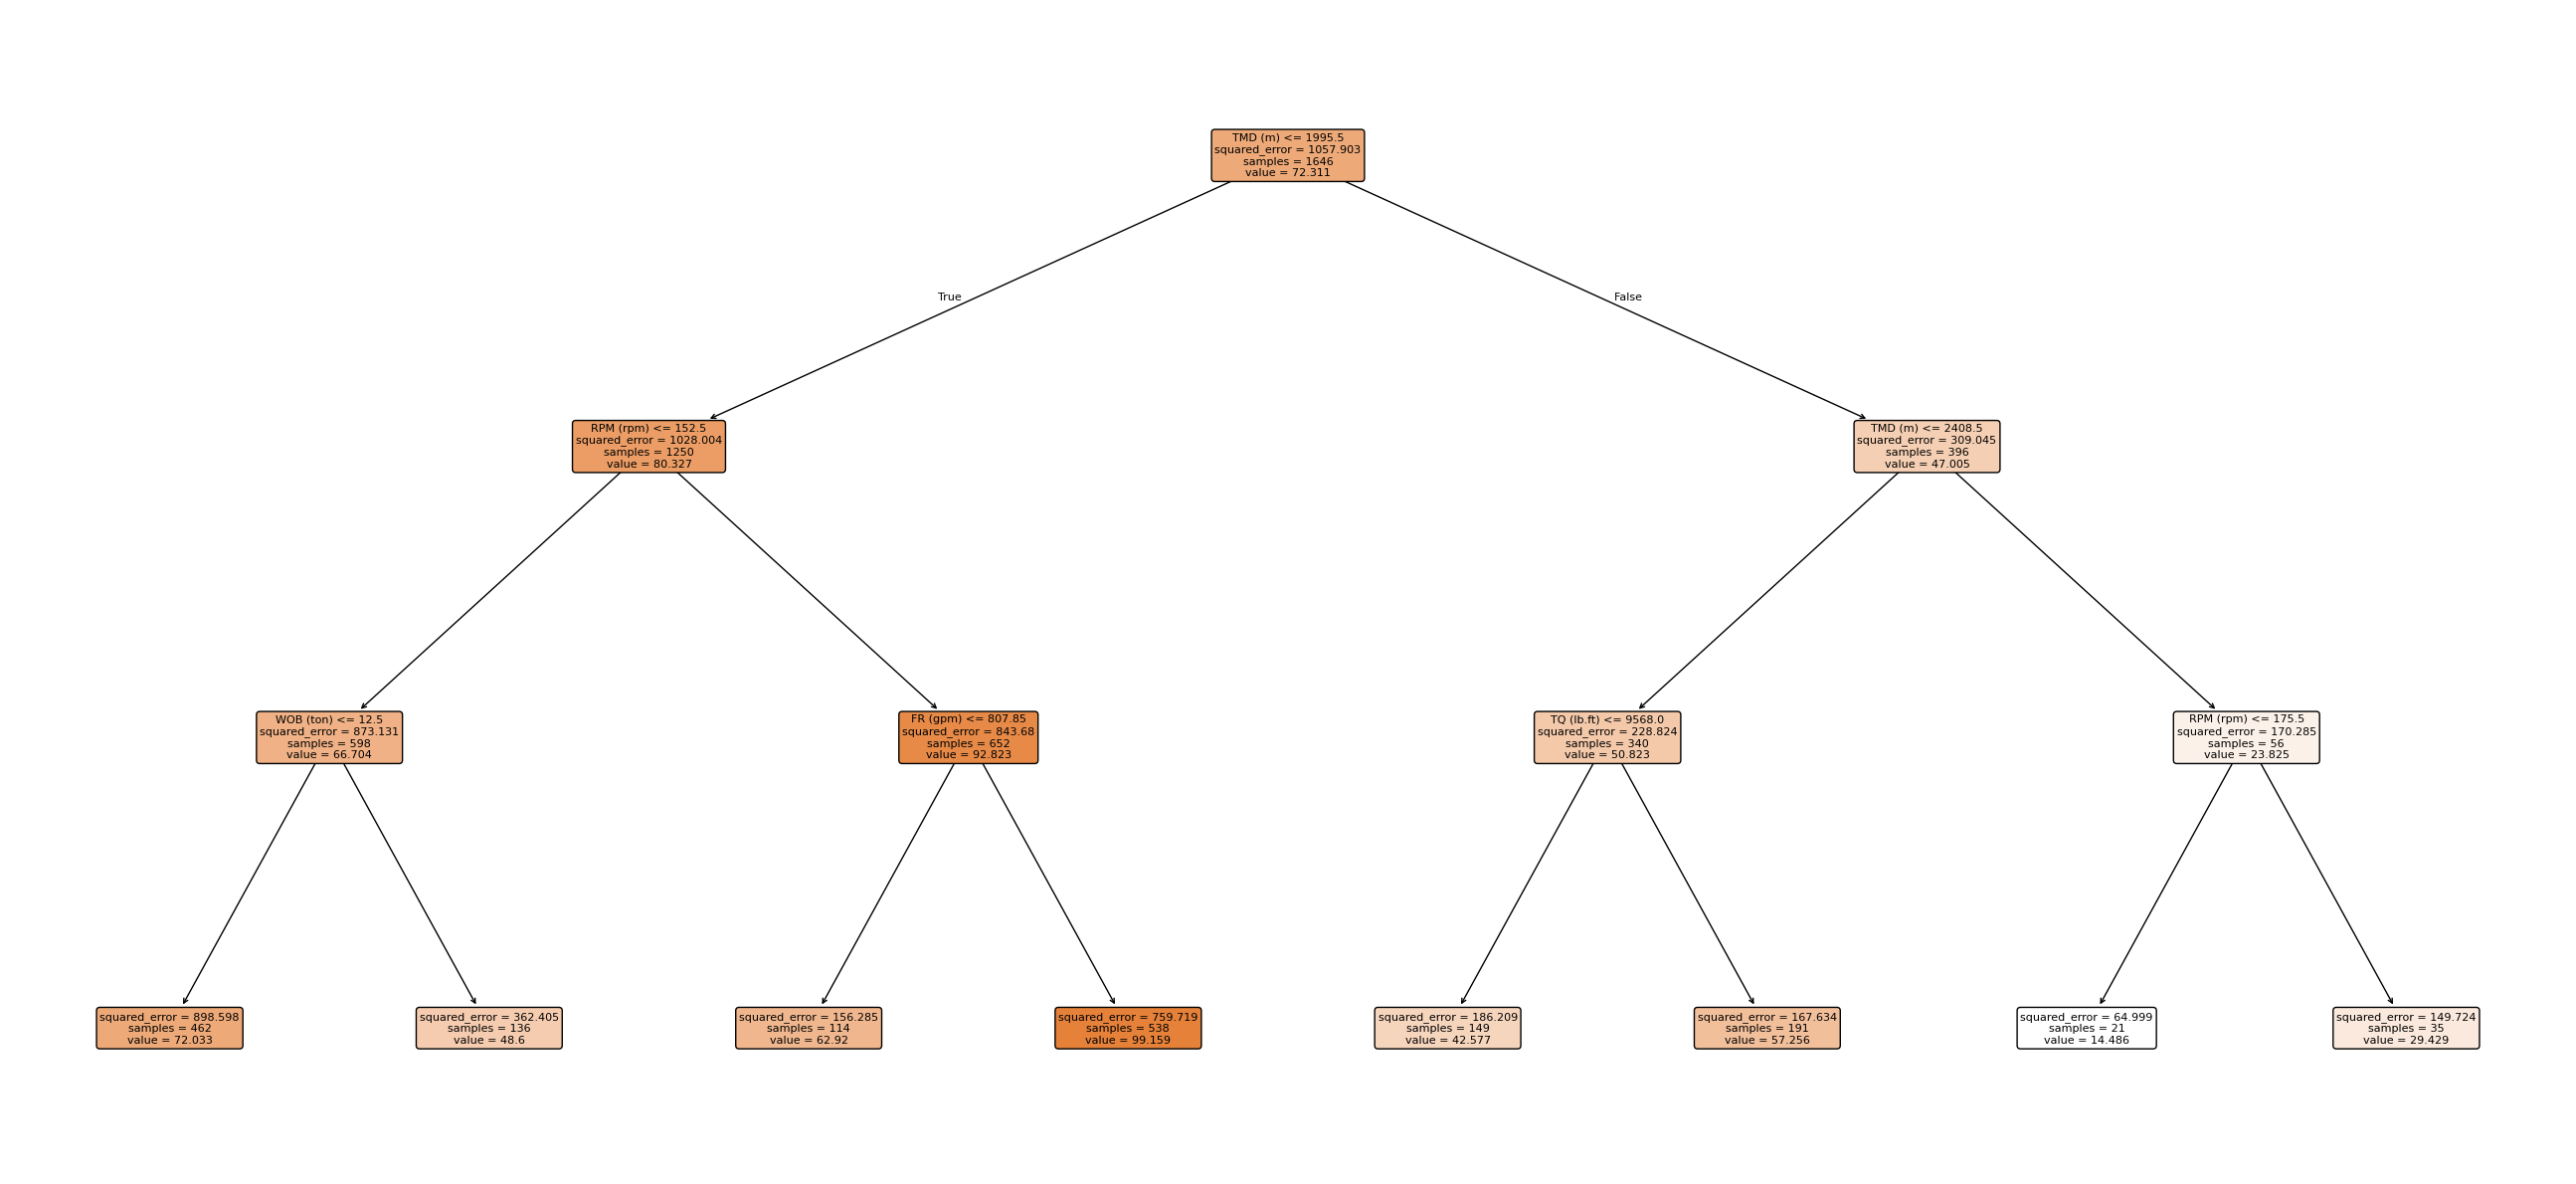

In [30]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
import matplotlib.pyplot as plt

# Pastikan X_train dan y_train sudah dibuat sebelumnya.
# Gunakan nama kolom jika X_train berupa DataFrame;
# jika berupa array, buat nama fitur otomatis.
if hasattr(X_train, "columns"):
    feature_names = list(X_train.columns)
else:
    feature_names = [f"Fitur {i}" for i in range(X_train.shape[1])]

# Buat dan latih model
dt_viz = DecisionTreeRegressor(max_depth=3, random_state=42)
dt_viz.fit(X_train, y_train)

# Tampilkan visualisasi pohon
fig, ax = plt.subplots(figsize=(26, 12))
plot_tree(
    dt_viz,
    feature_names=feature_names,
    filled=True,
    rounded=True,
    ax=ax,
    fontsize=8
)

plt.tight_layout()
plt.show()

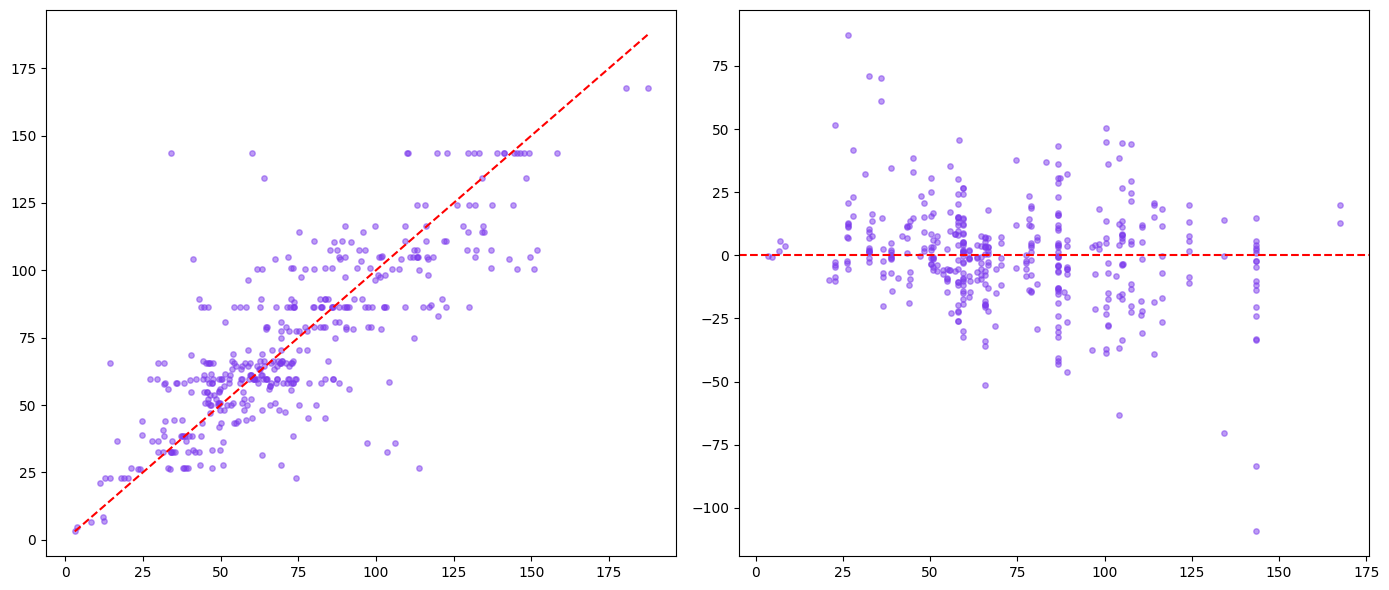

In [31]:
# Predicted vs Actual + Residual
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(y_test, y_pred_dt, alpha=0.5, s=15, color='#7c3aed')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
residuals_dt = y_test - y_pred_dt
axes[1].scatter(y_pred_dt, residuals_dt, alpha=0.5, s=15, color='#7c3aed')
axes[1].axhline(0, color='red', ls='--')
plt.tight_layout(); plt.show()

In [33]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Training Random Forest
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# Evaluasi model
mae = mean_absolute_error(y_test, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2 = r2_score(y_test, y_pred_rf)

print("Random Forest - Hasil Evaluasi:")
print(f"MAE  = {mae:.4f} m/hr")
print(f"RMSE = {rmse:.4f} m/hr")
print(f"R²   = {r2:.4f}")

Random Forest - Hasil Evaluasi:
MAE  = 11.4058 m/hr
RMSE = 16.4128 m/hr
R²   = 0.7530


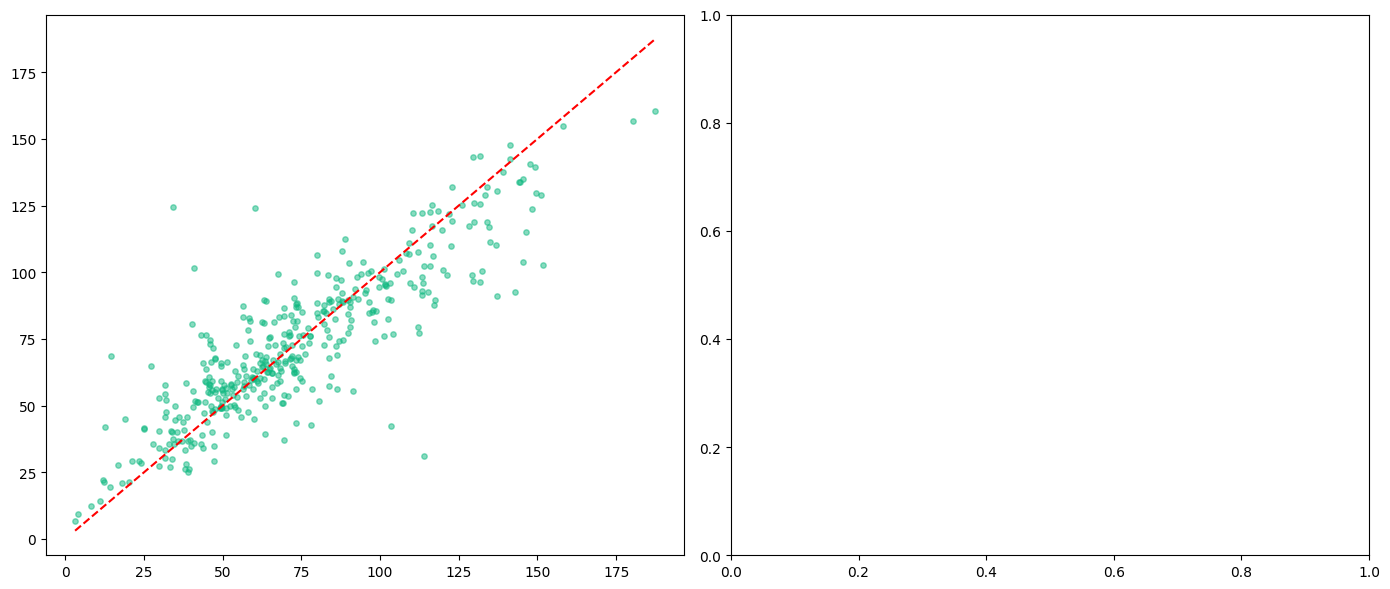

In [34]:
# Predicted vs Actual + Residual
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(y_test, y_pred_rf, alpha=0.5, s=15, color='#10b981')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.tight_layout(); plt.show()

🔑 Feature Importance (Random Forest):
   TMD (m)                0.1428 ███████
   RPM (rpm)              0.1411 ███████
   TVD (m)                0.1269 ██████
   BIT TIME (hr)          0.1084 █████
   TQ (lb.ft)             0.1060 █████
   FR (gpm)               0.0997 ████
   WOB (ton)              0.0924 ████
   FORMATION_CODE         0.0505 ██
   SPP (psi)              0.0473 ██
   RETURN (%)             0.0405 ██
   MW_DIFF                0.0376 █
   MW OUT (ppg)           0.0057 
   DEPTH_CAT_encoded      0.0006 
   MW IN (ppg)            0.0006 


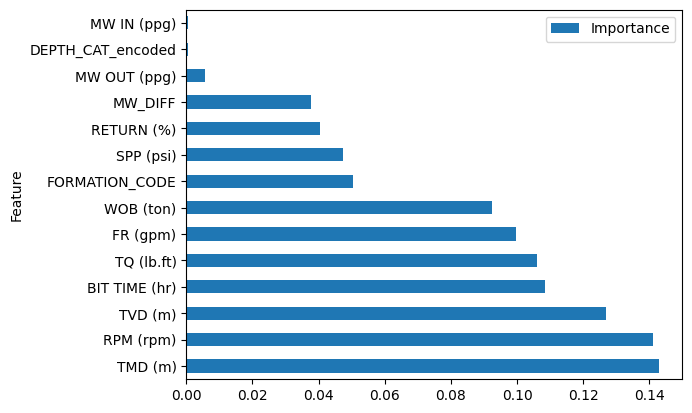

In [35]:
# Feature Importance
imp_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

print("🔑 Feature Importance (Random Forest):")
for _, row in imp_df.iterrows():
    bar = '█' * int(row['Importance'] * 50)
    print(f"   {row['Feature']:22s} {row['Importance']:.4f} {bar}")

imp_df.plot.barh(x='Feature', y='Importance'); plt.show()

In [36]:
# Tabel perbandingan
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest'],
    'MAE': [18.72, 14.01, 11.42],
    'RMSE': [29.33, 20.05, 16.44],
    'R²': [0.2112, 0.6315, 0.7523]
})
print(results.to_string(index=False))

            Model   MAE  RMSE     R²
Linear Regression 18.72 29.33 0.2112
    Decision Tree 14.01 20.05 0.6315
    Random Forest 11.42 16.44 0.7523


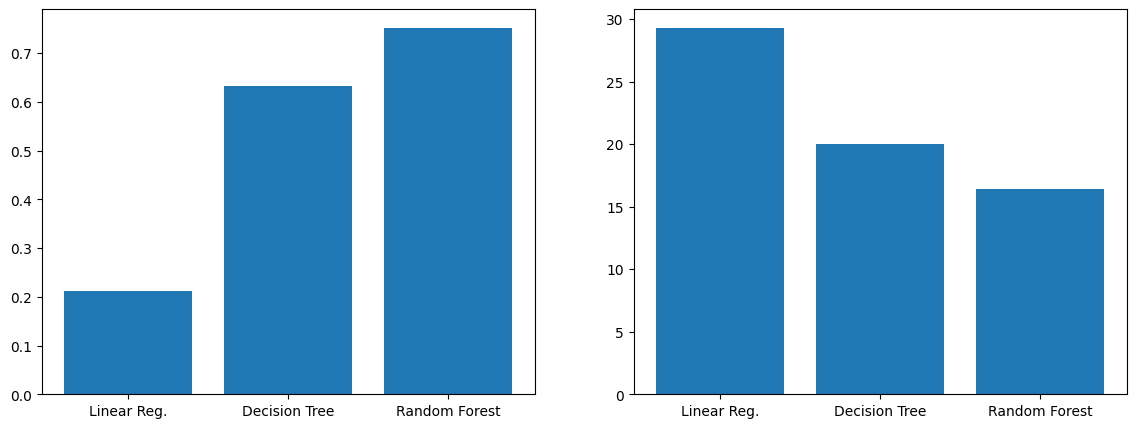

In [37]:
# Bar chart perbandingan R² dan RMSE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
models = ['Linear Reg.', 'Decision Tree', 'Random Forest']
axes[0].bar(models, results['R²'])
axes[1].bar(models, results['RMSE'])
plt.show()

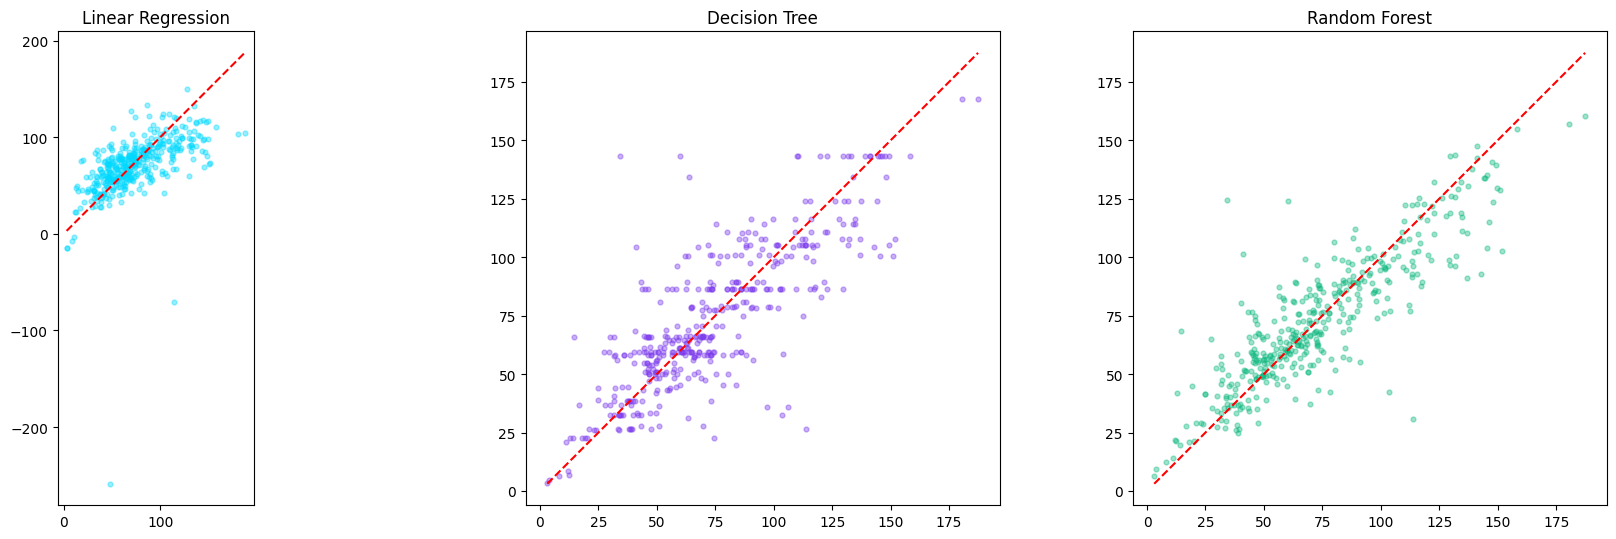

In [38]:
# Perbandingan Predicted vs Actual (3 model)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, y_pred, name, color in zip(axes,
    [y_pred_lr, y_pred_dt, y_pred_rf],
    ['Linear Regression', 'Decision Tree', 'Random Forest'],
    ['#00d9ff', '#7c3aed', '#10b981']):
    ax.scatter(y_test, y_pred, alpha=0.4, s=12, color=color)
    ax.plot([y_test.min(), y_test.max()],
            [y_test.min(), y_test.max()], 'r--')
    ax.set_title(name); ax.set_aspect('equal')
plt.tight_layout(); plt.show()

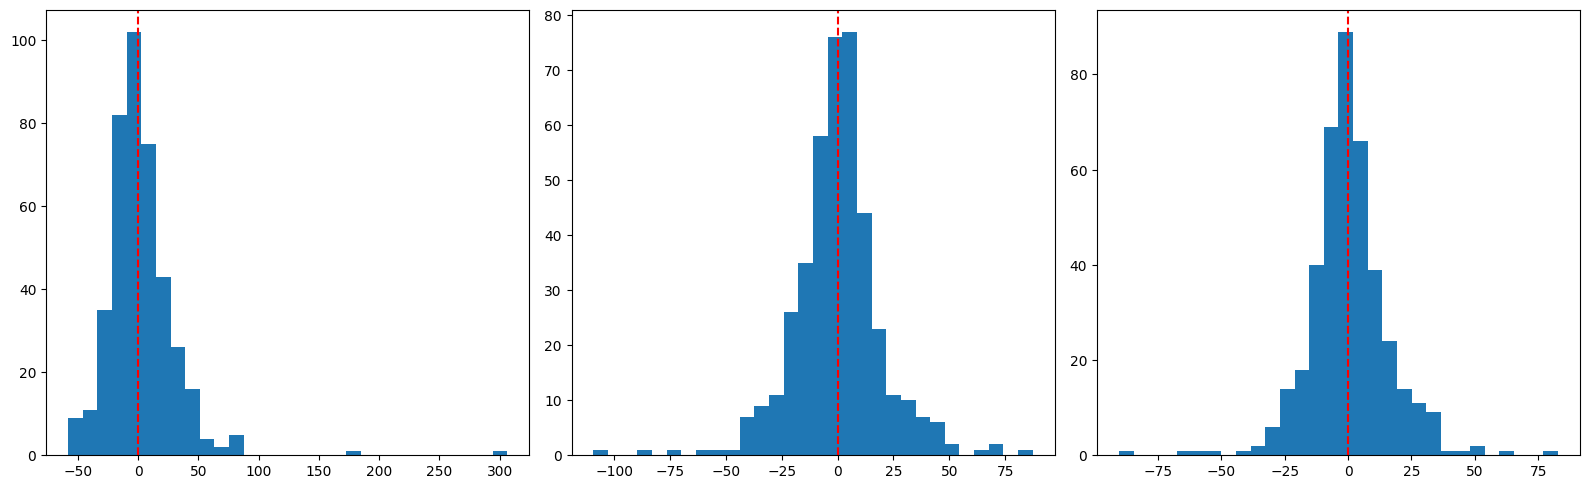

In [39]:
# Distribusi residual ketiga model
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, res, name in zip(axes,
    [y_test-y_pred_lr, y_test-y_pred_dt, y_test-y_pred_rf],
    ['Linear Regression', 'Decision Tree', 'Random Forest']):
    ax.hist(res, bins=30)
    ax.axvline(0, color='red', ls='--')
plt.tight_layout(); plt.show()

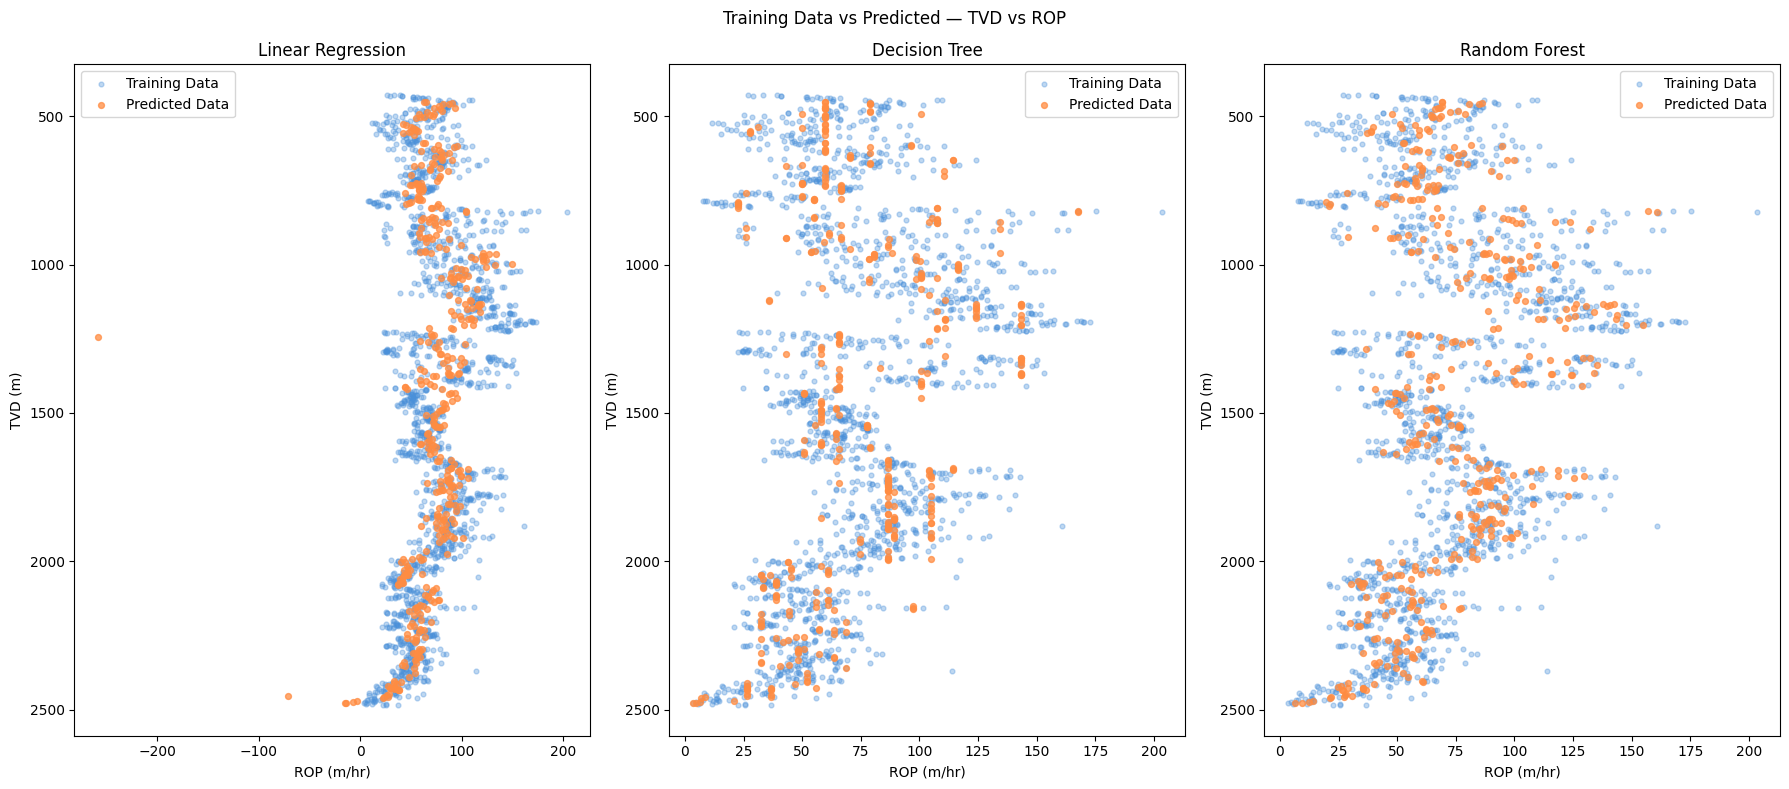

In [40]:
# TVD vs ROP — Training Data vs Predicted (ketiga model)
tvd_train = df.loc[X_train.index, 'TVD (m)']
tvd_test = df.loc[X_test.index, 'TVD (m)']

fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for ax, y_pred, name in zip(axes,
    [y_pred_lr, y_pred_dt, y_pred_rf],
    ['Linear Regression', 'Decision Tree', 'Random Forest']):
    ax.scatter(y_train, tvd_train, s=12, alpha=0.35,
              color='#4a90d9', label='Training Data')
    ax.scatter(y_pred, tvd_test, s=18, alpha=0.75,
              color='#ff8c42', label='Predicted Data')
    ax.invert_yaxis()
    ax.legend(); ax.set_title(name)
    ax.set_xlabel('ROP (m/hr)'); ax.set_ylabel('TVD (m)')
plt.suptitle('Training Data vs Predicted — TVD vs ROP')
plt.tight_layout(); plt.show()

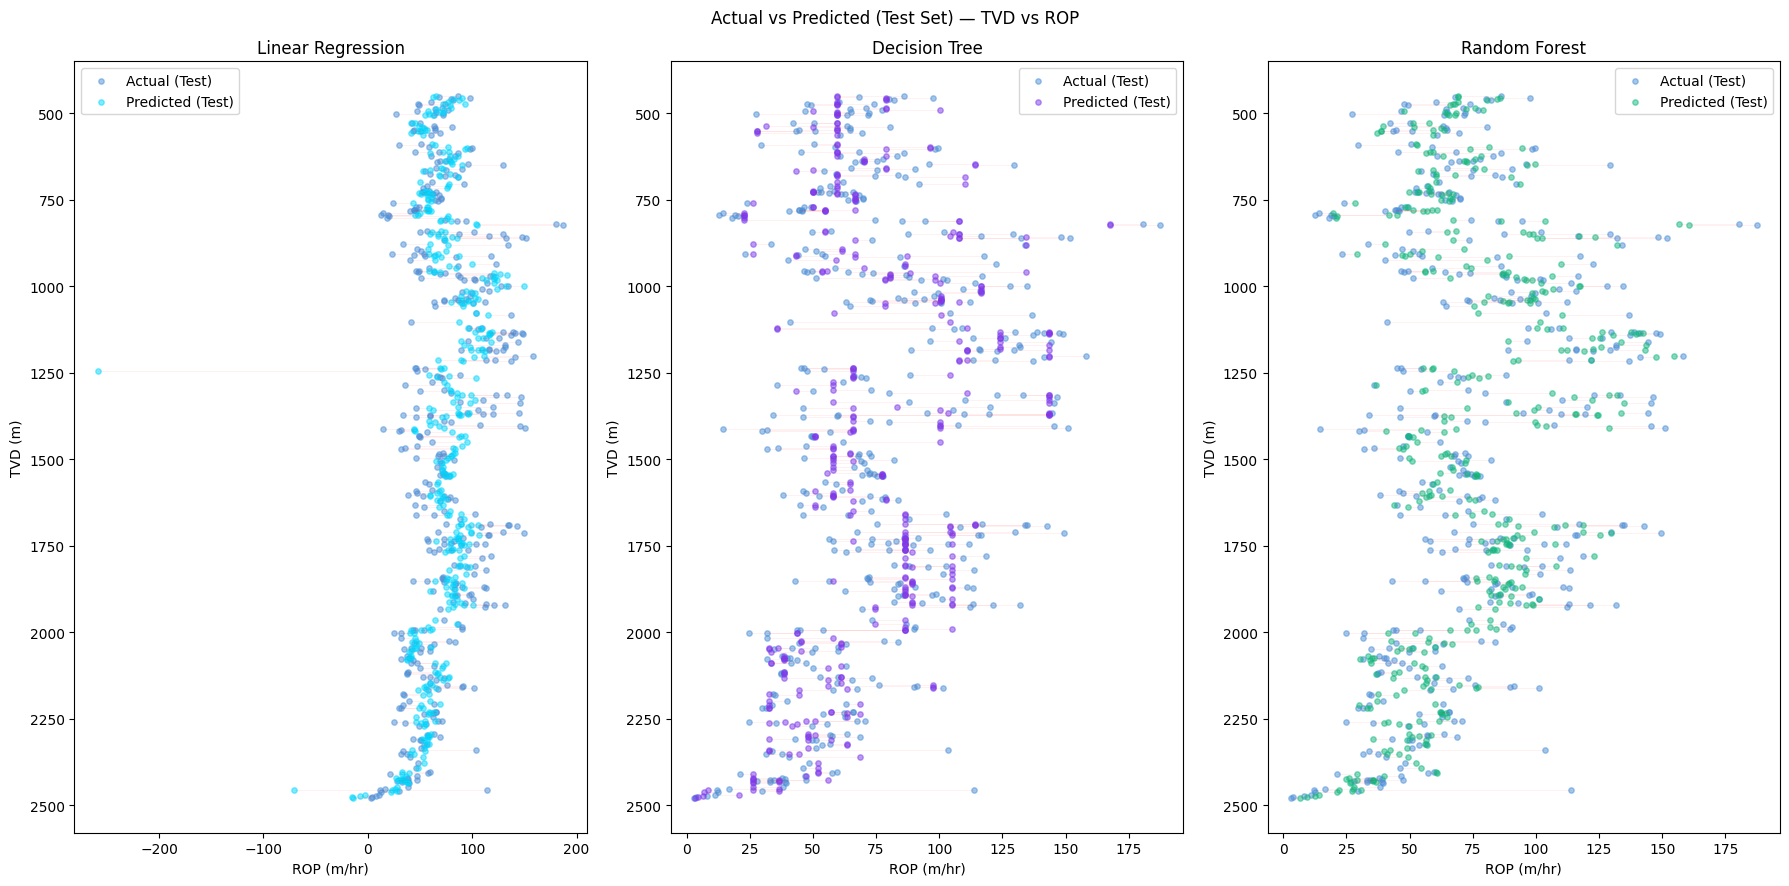

In [41]:
# Actual vs Predicted pada test set (dengan garis error)
fig, axes = plt.subplots(1, 3, figsize=(18, 9))
for ax, y_pred, name, color in zip(axes,
    [y_pred_lr, y_pred_dt, y_pred_rf],
    ['Linear Regression', 'Decision Tree', 'Random Forest'],
    ['#00d9ff', '#7c3aed', '#10b981']):
    ax.scatter(y_test, tvd_test, s=15, alpha=0.5,
              color='#4a90d9', label='Actual (Test)')
    ax.scatter(y_pred, tvd_test, s=15, alpha=0.5,
              color=color, label='Predicted (Test)')
    # Garis error horizontal
    for yt, yp, tvd in zip(y_test, y_pred, tvd_test):
        ax.plot([yt, yp], [tvd, tvd], color='red', alpha=0.08, lw=0.5)
    ax.invert_yaxis()
    ax.legend(); ax.set_title(name)
    ax.set_xlabel('ROP (m/hr)'); ax.set_ylabel('TVD (m)')
plt.suptitle('Actual vs Predicted (Test Set) — TVD vs ROP')
plt.tight_layout(); plt.show()

In [42]:
# Simpan model terbaik
import joblib
joblib.dump(rf, 'best_model_rf.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(oe, 'ordinal_encoder.pkl')
print("✅ Model, scaler, dan encoder berhasil disimpan!")

✅ Model, scaler, dan encoder berhasil disimpan!
